In [1]:
import numpy as np
import matplotlib
import PIL
import sklearn
import skimage
import tensorflow as tf


In [2]:
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("pillow:", PIL.__version__)
print("scikit-learn:", sklearn.__version__)
print("scikit-image:", skimage.__version__)
print("tensorflow:", tf.__version__)

numpy: 2.3.5
matplotlib: 3.10.6
pillow: 12.0.0
scikit-learn: 1.7.2
scikit-image: 0.25.2
tensorflow: 2.21.0


In [3]:
import os
import numpy as np
from PIL import Image

data_dir = "eurosat_image"     
classes = ['AnnualCrop', 'Forest', 'Residential', 'River', 'SeaLake']

X, y = [], []
for label, cls in enumerate(classes):
    folder = os.path.join(data_dir, cls)
    for fname in os.listdir(folder):
        img = Image.open(os.path.join(folder, fname)).convert('RGB').resize((64, 64))
        X.append(np.array(img))
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Images:", X.shape)
print("Labels:", y.shape)
print("Images per class:", dict(zip(classes, np.bincount(y))))

Images: (14500, 64, 64, 3)
Labels: (14500,)
Images per class: {'AnnualCrop': np.int64(3000), 'Forest': np.int64(3000), 'Residential': np.int64(3000), 'River': np.int64(2500), 'SeaLake': np.int64(3000)}


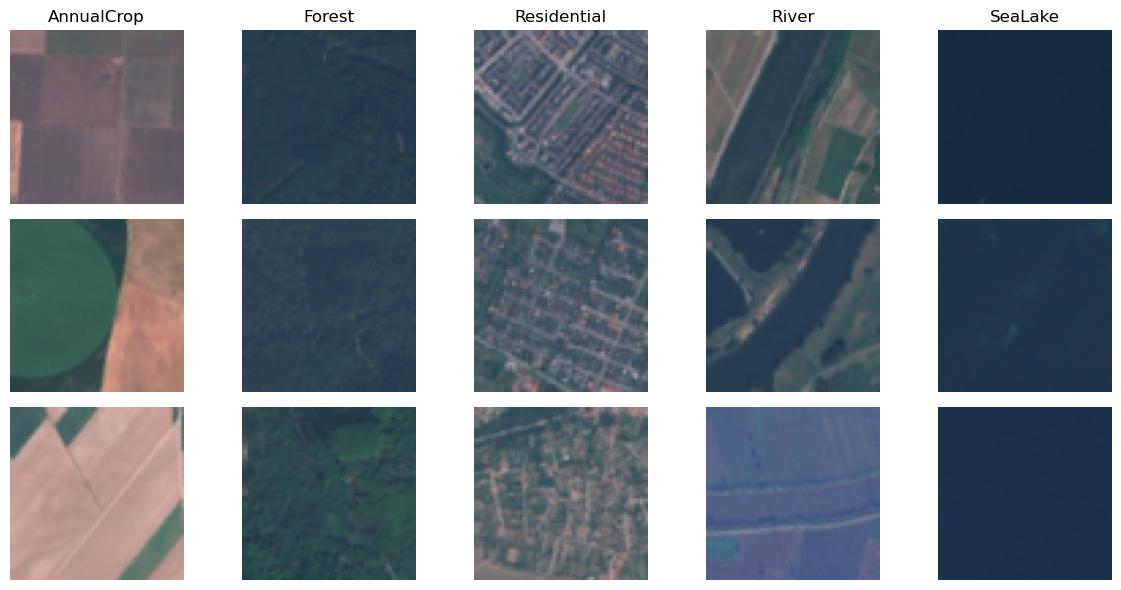

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
for i, cls in enumerate(classes):
    idxs = np.where(y == i)[0][:3]          
    for j, idx in enumerate(idxs):
        plt.subplot(3, 5, j * 5 + i + 1)
        plt.imshow(X[idx])
        if j == 0:
            plt.title(cls)
        plt.axis('off')
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

# 1) Normalize: pixel values from 0-255 to 0-1
X = X.astype('float32') / 255.0

# 2) Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)
print("Train per class:", np.bincount(y_train))
print("Test per class: ", np.bincount(y_test))

Train: (11600, 64, 64, 3) (11600,)
Test:  (2900, 64, 64, 3) (2900,)
Train per class: [2400 2400 2400 2000 2400]
Test per class:  [600 600 600 500 600]


In [7]:
from tensorflow import keras
from tensorflow.keras import layers

# 1) Flatten: each 64x64x3 image becomes one row of 12,288 numbers
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)
print("Flattened train:", X_train_flat.shape)

# 2) Build the ANN
model = keras.Sequential([
    layers.Input(shape=(X_train_flat.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(5, activation='softmax')
])

# 3) Choose how it learns
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Flattened train: (11600, 12288)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │       1,572,992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,581,573 (6.03 MB)

 Trainable params: 1,581,573 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train_flat, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


Epoch 1/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.4651 - loss: 1.3195 - val_accuracy: 0.6263 - val_loss: 1.0060
Epoch 2/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.5678 - loss: 1.0462 - val_accuracy: 0.5517 - val_loss: 1.0934
Epoch 3/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.6427 - loss: 0.9250 - val_accuracy: 0.6539 - val_loss: 0.9300
Epoch 4/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.6619 - loss: 0.8801 - val_accuracy: 0.6772 - val_loss: 0.8523
Epoch 5/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.6932 - loss: 0.8235 - val_accuracy: 0.6875 - val_loss: 0.8480
Epoch 6/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.6971 - loss: 0.8120 - val_accuracy: 0.6655 - val_loss: 0.8895
Epoch 7/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.6921 - loss: 0.8148 - val_accuracy: 0.6922 - val_loss: 0.7968
Epoch 8/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.7103 - loss: 0.7782 - val_accu

In [9]:
test_loss, test_acc = model.evaluate(X_test_flat, y_test, verbose=0)
print("Baseline test accuracy:", round(test_acc * 100, 2), "%")

Baseline test accuracy: 74.76 %


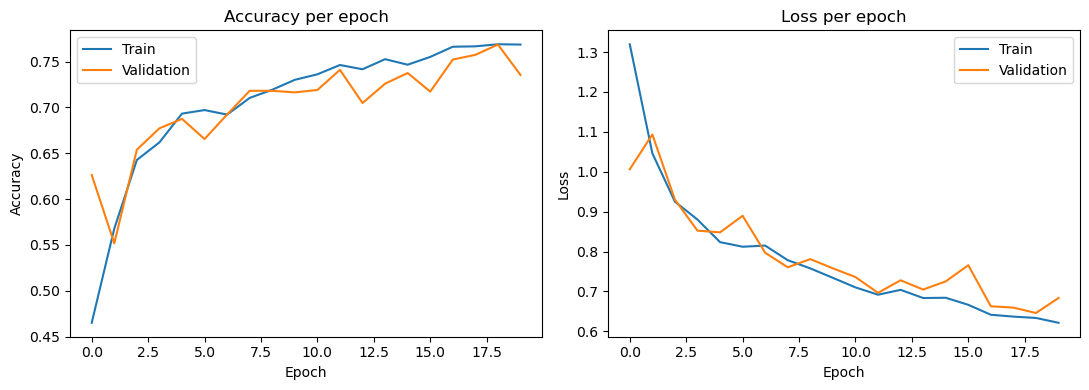

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy per epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

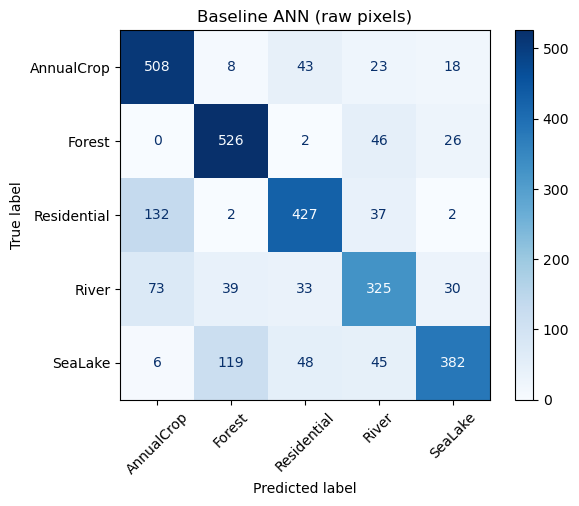

              precision    recall  f1-score   support

  AnnualCrop       0.71      0.85      0.77       600
      Forest       0.76      0.88      0.81       600
 Residential       0.77      0.71      0.74       600
       River       0.68      0.65      0.67       500
     SeaLake       0.83      0.64      0.72       600

    accuracy                           0.75      2900
   macro avg       0.75      0.74      0.74      2900
weighted avg       0.75      0.75      0.75      2900



In [11]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1) Predict on the test set
y_pred_probs = model.predict(X_test_flat, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2) Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Baseline ANN (raw pixels)')
plt.show()

# 3) Per-class report
print(classification_report(y_test, y_pred, target_names=classes))

In [12]:
from skimage.color import rgb2gray, rgb2hsv
from skimage.filters import sobel

def extract_features(img):
    feats = []

    # 1) Color statistics per channel (R, G, B): mean and std
    for c in range(3):
        feats.append(img[:, :, c].mean())
        feats.append(img[:, :, c].std())

    # 2) Color statistics in HSV space: mean and std of H, S, V
    hsv = rgb2hsv(img)
    for c in range(3):
        feats.append(hsv[:, :, c].mean())
        feats.append(hsv[:, :, c].std())

    # 3) Color histogram: 8 bins per channel
    for c in range(3):
        hist, _ = np.histogram(img[:, :, c], bins=8, range=(0, 1))
        feats.extend(hist / hist.sum())

    # 4) Edge (texture) features from the grayscale image
    edges = sobel(rgb2gray(img))
    feats.append(edges.mean())
    feats.append(edges.std())
    feats.append((edges > 0.1).mean())   # fraction of strong edge pixels

    return feats

F_train = np.array([extract_features(img) for img in X_train])
F_test = np.array([extract_features(img) for img in X_test])

print("Feature matrix train:", F_train.shape)
print("Feature matrix test: ", F_test.shape)

Feature matrix train: (11600, 39)
Feature matrix test:  (2900, 39)


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
F_train_scaled = scaler.fit_transform(F_train)   # learn mean/std from TRAIN only
F_test_scaled = scaler.transform(F_test)         # apply the same values to TEST

print("Before scaling (first 5 features, train mean):", F_train[:, :5].mean(axis=0).round(3))
print("After scaling  (first 5 features, train mean):", F_train_scaled[:, :5].mean(axis=0).round(3))
print("After scaling  (first 5 features, train std): ", F_train_scaled[:, :5].std(axis=0).round(3))

Before scaling (first 5 features, train mean): [0.302 0.077 0.351 0.05  0.386]
After scaling  (first 5 features, train mean): [-0. -0. -0.  0.  0.]
After scaling  (first 5 features, train std):  [1. 1. 1. 1. 1.]


In [14]:
# 1) Build the ANN (input is now 39 features, not 12,288 pixels)
model_fe = keras.Sequential([
    layers.Input(shape=(F_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(5, activation='softmax')
])

model_fe.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 2) Train
history_fe = model_fe.fit(
    F_train_scaled, y_train,
    epochs=40,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7606 - loss: 0.6565 - val_accuracy: 0.8659 - val_loss: 0.3959
Epoch 2/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8897 - loss: 0.3331 - val_accuracy: 0.9194 - val_loss: 0.2763
Epoch 3/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9202 - loss: 0.2494 - val_accuracy: 0.9310 - val_loss: 0.2279
Epoch 4/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9304 - loss: 0.2051 - val_accuracy: 0.9392 - val_loss: 0.1906
Epoch 5/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9409 - loss: 0.1772 - val_accuracy: 0.9397 - val_loss: 0.1759
Epoch 6/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9456 - loss: 0.1591 - val_accuracy: 0.9453 - val_loss: 0.1575
Epoch 7/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9495 - loss: 0.1455 - val_accuracy: 0.9483 - val_loss: 0.1498
Epoch 8/40
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9539 - loss: 0.1336 - val_accuracy: 0.

In [15]:
test_loss_fe, test_acc_fe = model_fe.evaluate(F_test_scaled, y_test, verbose=0)

print("Baseline (raw pixels) test accuracy:      ", round(test_acc * 100, 2), "%")
print("Feature-engineered ANN test accuracy:     ", round(test_acc_fe * 100, 2), "%")
print("Improvement:", round((test_acc_fe - test_acc) * 100, 2), "percentage points")

Baseline (raw pixels) test accuracy:       74.76 %
Feature-engineered ANN test accuracy:      96.31 %
Improvement: 21.55 percentage points


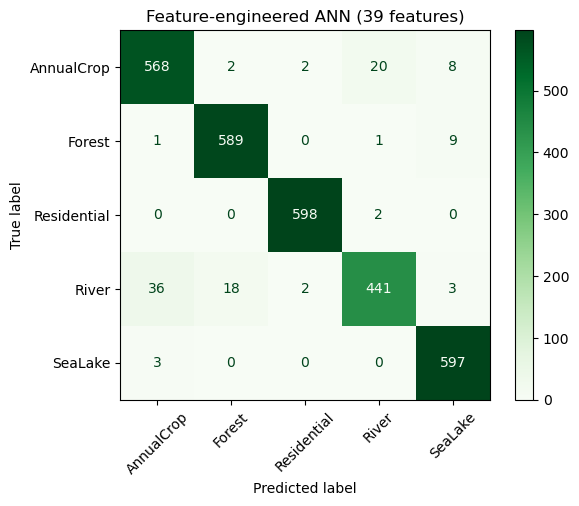

              precision    recall  f1-score   support

  AnnualCrop       0.93      0.95      0.94       600
      Forest       0.97      0.98      0.97       600
 Residential       0.99      1.00      1.00       600
       River       0.95      0.88      0.91       500
     SeaLake       0.97      0.99      0.98       600

    accuracy                           0.96      2900
   macro avg       0.96      0.96      0.96      2900
weighted avg       0.96      0.96      0.96      2900



In [16]:
y_pred_fe = np.argmax(model_fe.predict(F_test_scaled, verbose=0), axis=1)

cm_fe = confusion_matrix(y_test, y_pred_fe)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_fe, display_labels=classes)
disp.plot(cmap='Greens', xticks_rotation=45)
plt.title('Feature-engineered ANN (39 features)')
plt.show()

print(classification_report(y_test, y_pred_fe, target_names=classes))

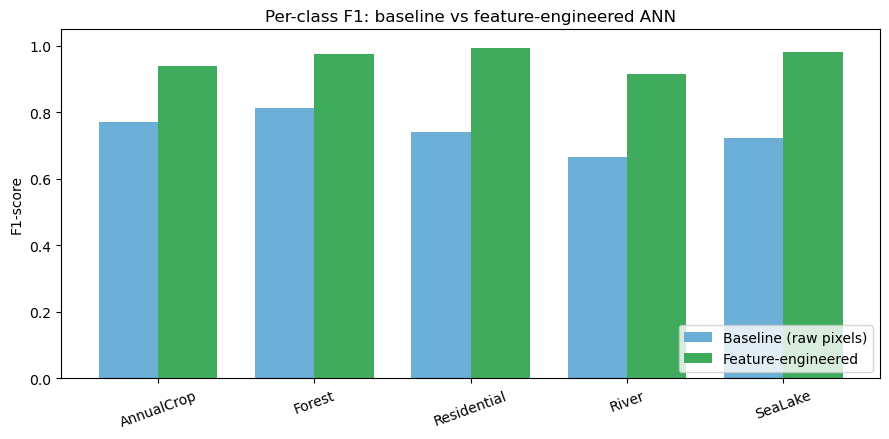

In [17]:
from sklearn.metrics import f1_score

f1_base = f1_score(y_test, y_pred, average=None)
f1_fe = f1_score(y_test, y_pred_fe, average=None)

x = np.arange(len(classes))
width = 0.38

plt.figure(figsize=(9, 4.5))
plt.bar(x - width/2, f1_base, width, label='Baseline (raw pixels)', color='#6baed6')
plt.bar(x + width/2, f1_fe, width, label='Feature-engineered', color='#41ab5d')
plt.xticks(x, classes, rotation=20)
plt.ylabel('F1-score')
plt.ylim(0, 1.05)
plt.title('Per-class F1: baseline vs feature-engineered ANN')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [18]:
os.makedirs("report_figures", exist_ok=True)

# 1) Sample images grid
plt.figure(figsize=(12, 6))
for i, cls in enumerate(classes):
    idxs = np.where(y == i)[0][:3]
    for j, idx in enumerate(idxs):
        plt.subplot(3, 5, j * 5 + i + 1)
        plt.imshow(X[idx])
        if j == 0:
            plt.title(cls)
        plt.axis('off')
plt.tight_layout()
plt.savefig("report_figures/1_samples.png", dpi=150)
plt.close()

# 2) Learning curves (function used for both models)
def save_curves(h, title, fname):
    plt.figure(figsize=(11, 4))
    plt.subplot(1, 2, 1)
    plt.plot(h.history['accuracy'], label='Train')
    plt.plot(h.history['val_accuracy'], label='Validation')
    plt.title(title + ': accuracy')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(h.history['loss'], label='Train')
    plt.plot(h.history['val_loss'], label='Validation')
    plt.title(title + ': loss')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.close()

save_curves(history, "Baseline (raw pixels)", "report_figures/2_curves_baseline.png")
save_curves(history_fe, "Feature-engineered", "report_figures/3_curves_features.png")

# 3) Confusion matrices
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', xticks_rotation=45)
plt.title('Baseline ANN (raw pixels)')
plt.tight_layout()
plt.savefig("report_figures/4_cm_baseline.png", dpi=150)
plt.close()

ConfusionMatrixDisplay(cm_fe, display_labels=classes).plot(cmap='Greens', xticks_rotation=45)
plt.title('Feature-engineered ANN')
plt.tight_layout()
plt.savefig("report_figures/5_cm_features.png", dpi=150)
plt.close()

# 4) F1 comparison bar chart
plt.figure(figsize=(9, 4.5))
plt.bar(x - width/2, f1_base, width, label='Baseline (raw pixels)', color='#6baed6')
plt.bar(x + width/2, f1_fe, width, label='Feature-engineered', color='#41ab5d')
plt.xticks(x, classes, rotation=20)
plt.ylabel('F1-score'); plt.ylim(0, 1.05)
plt.title('Per-class F1: baseline vs feature-engineered ANN')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("report_figures/6_f1_comparison.png", dpi=150)
plt.close()

print(os.listdir("report_figures"))

['1_samples.png', '2_curves_baseline.png', '3_curves_features.png', '4_cm_baseline.png', '5_cm_features.png', '6_f1_comparison.png']


In [19]:
import joblib

model.save("baseline_model.keras")
model_fe.save("feature_model.keras")
joblib.dump(scaler, "feature_scaler.pkl")
print("Saved")

Saved
